# Discovering Cricket Data - Session 2: from one match to 4,484

Session 1 explored a single T20 international. This session loads every match in the
Cricsheet T20I download, corrects a few mistakes from Session 1, and asks some
bigger questions of the data.

## Load every ball-by-ball file

In [1]:
import csv
import glob
import os

import numpy as np
import pandas as pd

DATA_DIR = '../data/t20s_csv2'

# Every match has two files: <id>.csv (ball-by-ball) and <id>_info.csv (match info)
ball_files = sorted(f for f in glob.glob(f'{DATA_DIR}/*.csv') if not f.endswith('_info.csv'))
info_files = sorted(glob.glob(f'{DATA_DIR}/*_info.csv'))
print(f"{len(ball_files)} ball-by-ball files, {len(info_files)} info files")

# Read 'ball' as text: '0.10' (the 10th delivery of the first over) is not the same as '0.1'
dtypes = {'match_id': str, 'season': str, 'ball': str,
          'wicket_type': str, 'player_dismissed': str,
          'other_wicket_type': str, 'other_player_dismissed': str}
deliveries = pd.concat((pd.read_csv(f, dtype=dtypes) for f in ball_files), ignore_index=True)
print(f"{len(deliveries):,} deliveries loaded")

4484 ball-by-ball files, 4484 info files


1,013,937 deliveries loaded


## The `ball` column isn't a number

In [2]:
over_ball = deliveries['ball'].str.split('.', expand=True).astype(int)
deliveries['over'] = over_ball[0] + 1          # 1-20, the way commentators count
deliveries['ball_in_over'] = over_ball[1]

print(f"Deliveries numbered .10 or higher: {(deliveries['ball_in_over'] >= 10).sum():,}")
print(f"Read as floats, '0.10' == '0.1': {float('0.10') == float('0.1')}")

longest = deliveries.loc[deliveries['ball_in_over'].idxmax()]
print(f"\nLongest over: {longest['ball_in_over']} deliveries - {longest['bowler']} "
      f"({longest['bowling_team']} v {longest['batting_team']}, {longest['start_date']})")

Deliveries numbered .10 or higher: 1,458
Read as floats, '0.10' == '0.1': True

Longest over: 19 deliveries - Emilia Toro (Chile v Argentina, 2023-10-14)


## Helper columns, and super overs

In [3]:
# Wides and no-balls are re-bowled, so they don't count towards the over
deliveries['legal'] = deliveries['wides'].isna() & deliveries['noballs'].isna()
deliveries['total_runs'] = deliveries['runs_off_bat'] + deliveries['extras']

# A batter retiring hurt isn't a wicket, and run outs aren't credited to the bowler
deliveries['wicket'] = (deliveries['player_dismissed'].notna()
                        & ~deliveries['wicket_type'].isin(['retired hurt', 'retired not out']))
BOWLER_WICKETS = ['bowled', 'caught', 'caught and bowled', 'lbw', 'stumped', 'hit wicket']
deliveries['bowler_wicket'] = deliveries['wicket_type'].isin(BOWLER_WICKETS)

print(deliveries['wicket_type'].value_counts())
print()
print(deliveries['innings'].value_counts().sort_index())

# Innings 3 and up are super overs - keep them out of the analysis
deliveries = deliveries[deliveries['innings'] <= 2].copy()

wicket_type
caught                   28432
bowled                   12992
run out                   5799
lbw                       4846
stumped                   2205
caught and bowled         1917
retired hurt                70
hit wicket                  51
retired out                 18
obstructing the field        7
retired not out              7
hit the ball twice           1
Name: count, dtype: int64

innings
1    546611
2    466869
3       235
4       204
5         7
6         6
7         4
8         1
Name: count, dtype: int64


## Parse the match info files

In [4]:
def read_info(path):
    """Flatten one <id>_info.csv into a dict, plus its player registry rows."""
    match = {'match_id': os.path.basename(path).removesuffix('_info.csv'), 'teams': []}
    registry = []
    with open(path, newline='') as f:
        for row in csv.reader(f):
            if row[0] != 'info':
                continue
            key = row[1]
            if key == 'team':
                match['teams'].append(row[2])
            elif key == 'registry':
                registry.append((match['match_id'], row[3], row[4]))  # info,registry,people,<name>,<id>
            elif key not in ('player', 'players', 'umpire'):
                match.setdefault(key, row[2])  # a few matches list two dates - keep the first
    return match, registry


parsed = [read_info(f) for f in info_files]
matches = pd.DataFrame([m for m, _ in parsed])
registry = pd.DataFrame([r for _, reg in parsed for r in reg], columns=['match_id', 'name', 'player_id'])

matches['date'] = pd.to_datetime(matches['date'], format='%Y/%m/%d')
matches['year'] = matches['date'].dt.year

# The 12 current ICC full members - matches between two of them are the most comparable over time
FULL_MEMBERS = {'Afghanistan', 'Australia', 'Bangladesh', 'England', 'India', 'Ireland',
                'New Zealand', 'Pakistan', 'South Africa', 'Sri Lanka', 'West Indies', 'Zimbabwe'}
matches['full_members'] = matches['teams'].apply(lambda teams: set(teams) <= FULL_MEMBERS)

print(f"{len(matches):,} matches, {matches['date'].min():%d %b %Y} to {matches['date'].max():%d %b %Y}")
print(matches['gender'].value_counts())
print(matches['outcome'].value_counts())
print(matches['method'].value_counts())
matches[['match_id', 'date', 'gender', 'teams', 'venue', 'toss_winner', 'toss_decision', 'winner']].head()

4,484 matches, 17 Feb 2005 to 26 Jul 2025
gender
male      2860
female    1624
Name: count, dtype: int64
outcome
no result    85
tie          43
Name: count, dtype: int64
method
D/L        154
Awarded      2
Name: count, dtype: int64


,match_id,date,gender,teams,venue,toss_winner,toss_decision,winner
0,1001349,2017-02-17,male,"[Australia, Sri Lanka]",Melbourne Cricket Ground,Sri Lanka,field,Sri Lanka
1,1001351,2017-02-19,male,"[Australia, Sri Lanka]","Simonds Stadium, South Geelong",Sri Lanka,field,Sri Lanka
2,1001353,2017-02-22,male,"[Australia, Sri Lanka]",Adelaide Oval,Sri Lanka,field,Australia
3,1004729,2016-09-05,male,"[Ireland, Hong Kong]","Bready Cricket Club, Magheramason",Hong Kong,bat,Hong Kong
4,1007655,2016-06-18,male,"[Zimbabwe, India]",Harare Sports Club,India,field,Zimbabwe


## Join and save

In [5]:
deliveries = deliveries.merge(matches[['match_id', 'gender', 'year', 'full_members']], on='match_id')

os.makedirs('../data/processed', exist_ok=True)
deliveries.to_parquet('../data/processed/deliveries.parquet', index=False)
matches.to_parquet('../data/processed/matches.parquet', index=False)
print(f"Saved {len(deliveries):,} deliveries and {len(matches):,} matches to ../data/processed/")

Saved 1,013,480 deliveries and 4,484 matches to ../data/processed/


## Session 1's scorecard, corrected

In [6]:
def overs(legal_balls):
    """Cricket notation: 116 legal balls is '19.2' (19 overs and 2 balls), not 19.33."""
    return f"{legal_balls // 6}.{legal_balls % 6}"


match = deliveries[deliveries['match_id'] == '1327228']
for innings_no, inns in match.groupby('innings'):
    runs, wickets, legal = inns['total_runs'].sum(), inns['wicket'].sum(), inns['legal'].sum()
    print(f"Innings {innings_no}: {inns['batting_team'].iloc[0]} {runs}/{wickets} "
          f"in {overs(legal)} overs (run rate {runs / legal * 6:.2f})")

Innings 1: Pakistan 158/7 in 20.0 overs (run rate 7.90)
Innings 2: England 160/4 in 19.2 overs (run rate 8.28)


## How T20 internationals have grown

In [7]:
per_year = (pd.crosstab(matches['year'], matches['gender'])
            .rename(columns={'male': 'men', 'female': 'women'})[['men', 'women']])
per_year['total'] = per_year.sum(axis=1)

# How many of the men's matches were between two full members?
men_matches = matches[matches['gender'] == 'male']
per_year['men_full_v_full'] = men_matches.groupby('year')['full_members'].sum()
per_year

gender,men,women,total,men_full_v_full
year,,,,
2005,3,0,3,3
2006,8,0,8,8
2007,36,0,36,31
2008,15,0,15,12
2009,48,4,52,44
2010,56,4,60,52
2011,21,2,23,21
2012,72,32,104,61
2013,42,18,60,32


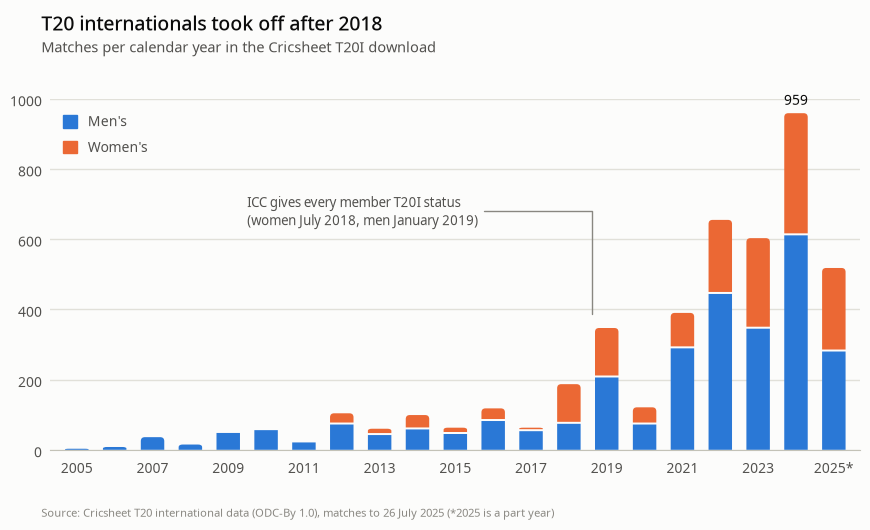

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from plotting import SOURCE, column, new_figure, px_to_data_y, save_both, titles

last_match = matches['date'].max()
source = f"{SOURCE}, matches to {last_match.day} {last_match:%B %Y}"


def plot_matches_per_year(theme, per_year, source):
    fig, ax = new_figure(theme, figsize=(9, 5.4))
    fig.subplots_adjust(left=0.07, right=0.97, top=0.80, bottom=0.15)
    years = per_year.index.to_numpy()
    ax.set_xlim(years.min() - 0.7, years.max() + 0.7)
    y_top = max(1000, int(np.ceil(per_year['total'].max() / 200)) * 200)
    ax.set_ylim(0, y_top)
    width, gap = 0.62, px_to_data_y(ax, 2)

    for year, row in per_year.iterrows():
        column(ax, year, 0, row['men'], width, theme['men'], round_top=row['women'] == 0)
        if row['women']:
            column(ax, year, row['men'] + gap, row['total'], width, theme['women'])

    peak = per_year['total'].idxmax()
    ax.annotate(f"{per_year.loc[peak, 'total']:,}", (peak, per_year.loc[peak, 'total']),
                xytext=(0, 6), textcoords='offset points', ha='center', color=theme['ink'], fontsize=10)
    ax.annotate('ICC gives every member T20I status\n(women July 2018, men January 2019)',
                xy=(2018.6, 380), xytext=(2009.5, 640), color=theme['ink_2'], fontsize=9.5,
                arrowprops=dict(arrowstyle='-', color=theme['muted'], linewidth=1,
                                connectionstyle='angle,angleA=0,angleB=90'))

    ticks = years[::2]
    ax.set_xticks(ticks, [f'{y}*' if y == years.max() else str(y) for y in ticks])
    ax.set_yticks(range(0, y_top + 1, 200))
    ax.legend(handles=[Patch(color=theme['men'], label="Men's"), Patch(color=theme['women'], label="Women's")],
              loc='upper left', frameon=False, labelcolor=theme['ink_2'], handlelength=1, handleheight=1)
    titles(fig, theme, 'T20 internationals took off after 2018',
           'Matches per calendar year in the Cricsheet T20I download',
           source=f'{source} (*{years.max()} is a part year)')
    return fig


save_both(plot_matches_per_year, 'matches-per-year', per_year, source)

## The shape of an innings, then and now

In [9]:
last_year = matches['year'].max()
ERAS = dict(bins=[2004, 2014, 2022, last_year], labels=['2005-14', '2015-22', f'2023-{last_year % 100:02d}'])

fm_men = deliveries[(deliveries['gender'] == 'male') & deliveries['full_members']].copy()
fm_men['era'] = pd.cut(fm_men['year'], **ERAS)
fm_men['phase'] = pd.cut(fm_men['over'], bins=[0, 6, 15, 20],
                         labels=['powerplay (1-6)', 'middle (7-15)', 'death (16-20)'])


def rates(df, by):
    g = df.groupby(by, observed=True).agg(runs=('total_runs', 'sum'), legal=('legal', 'sum'),
                                          wickets=('wicket', 'sum'))
    return pd.DataFrame({'runs_per_over': g['runs'] / g['legal'] * 6,
                         'wickets_per_over': g['wickets'] / g['legal'] * 6}).round(2)


rates(fm_men, ['era', 'phase']).unstack('phase')

runs_per_over                             wickets_per_over  \
phase   powerplay (1-6) middle (7-15) death (16-20)  powerplay (1-6)   
era                                                                    
2005-14            7.39          7.31          9.14             0.27   
2015-22            7.87          7.77          9.55             0.27   
2023-25            8.42          8.25          9.70             0.30   

                                     
phase   middle (7-15) death (16-20)  
era                                  
2005-14          0.28          0.54  
2015-22          0.28          0.53  
2023-25          0.31          0.55

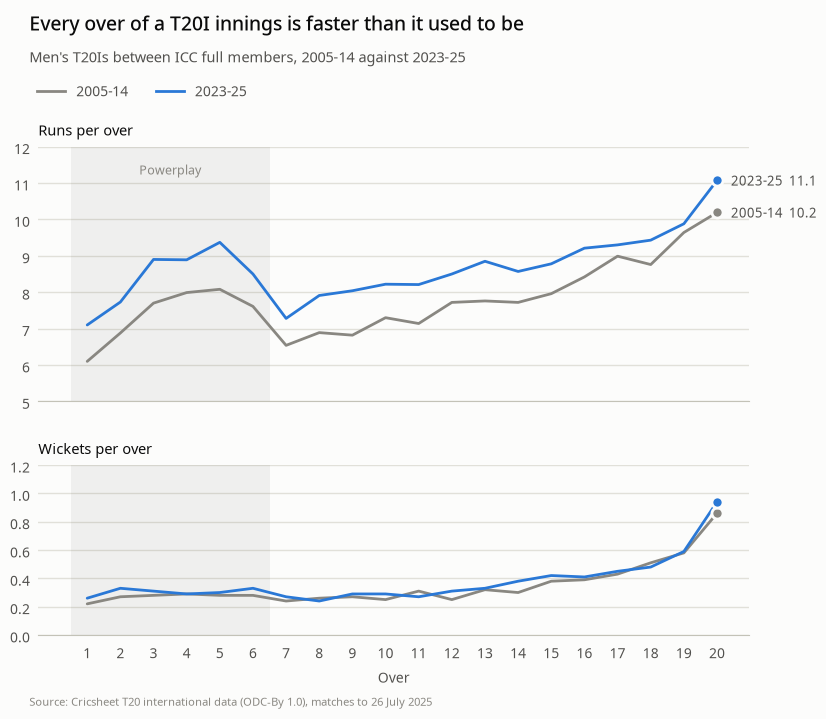

In [10]:
by_over = rates(fm_men, ['era', 'over'])


def plot_innings_shape(theme, by_over, source):
    fig, (top, bottom) = new_figure(theme, nrows=2, figsize=(9, 7.4), sharex=True,
                                    gridspec_kw={'height_ratios': [3, 2], 'hspace': 0.3})
    fig.subplots_adjust(left=0.07, right=0.86, top=0.78, bottom=0.12)
    first_era, last_era = ERAS['labels'][0], ERAS['labels'][-1]
    series = [(first_era, theme['context']), (last_era, theme['men'])]
    panels = [(top, 'runs_per_over', 'Runs per over'), (bottom, 'wickets_per_over', 'Wickets per over')]

    for ax, metric, label in panels:
        ax.axvspan(0.5, 6.5, color=theme['wash'], alpha=0.05, linewidth=0)
        for era, color in series:
            s = by_over.loc[era, metric]
            ax.plot(s.index, s.values, color=color, linewidth=2, solid_joinstyle='round', solid_capstyle='round')
            ax.scatter(s.index[-1], s.iloc[-1], s=64, color=color, edgecolor=theme['surface'], linewidth=2, zorder=3)
            if ax is top:  # the wickets lines finish too close together to label without clashing
                ax.annotate(f'{era}  {s.iloc[-1]:.1f}', (s.index[-1], s.iloc[-1]), xytext=(10, 0),
                            textcoords='offset points', va='center', color=theme['ink_2'], fontsize=9.5)
        ax.set_title(label, loc='left', color=theme['ink'], fontsize=10.5, pad=8)

    top.set_ylim(5, 12)
    bottom.set_ylim(0, 1.2)
    top.text(3.5, 11.6, 'Powerplay', ha='center', va='top', color=theme['muted'], fontsize=9)
    bottom.set_xticks(range(1, 21))
    bottom.set_xlabel('Over')
    fig.legend(handles=[plt.Line2D([], [], color=c, linewidth=2, label=era) for era, c in series],
               loc='upper left', bbox_to_anchor=(0.055, 0.885), ncol=2, frameon=False, labelcolor=theme['ink_2'])
    titles(fig, theme, 'Every over of a T20I innings is faster than it used to be',
           f"Men's T20Is between ICC full members, {first_era} against {last_era}", source)
    return fig


save_both(plot_innings_shape, 'innings-shape', by_over, source)

## Are scores going up?

In [11]:
innings = (deliveries.groupby(['match_id', 'innings'])
           .agg(team=('batting_team', 'first'), runs=('total_runs', 'sum'),
                wickets=('wicket', 'sum'), legal=('legal', 'sum'))
           .reset_index()
           .merge(matches[['match_id', 'gender', 'year', 'full_members', 'method', 'outcome',
                           'winner', 'toss_winner', 'toss_decision']], on='match_id'))

# First innings between full members, leaving out rain-affected (D/L) and abandoned matches
first = innings[(innings['innings'] == 1) & innings['full_members']
                & innings['method'].isna() & (innings['outcome'] != 'no result')].copy()
first['era'] = pd.cut(first['year'], **ERAS)
first['200_plus'] = first['runs'] >= 200

(first.groupby(['gender', 'era'], observed=True)
      .agg(innings=('runs', 'size'), average=('runs', 'mean'), median=('runs', 'median'),
           share_200_plus=('200_plus', 'mean'))
      .round(2))

innings  average  median  share_200_plus
gender era                                              
female 2005-14       96   116.81   115.5            0.00
       2015-22      296   133.19   133.0            0.02
       2023-25      178   139.94   141.0            0.04
male   2005-14      286   154.90   153.5            0.08
       2015-22      462   164.01   165.0            0.14
       2023-25      177   170.90   174.0            0.24

## Does winning the toss matter?

In [12]:
# Matches with a winner, leaving out D/L results and awarded matches
decided = matches[matches['winner'].notna() & matches['method'].isna()].copy()
batted_first = innings.loc[innings['innings'] == 1, ['match_id', 'team']].rename(columns={'team': 'batted_first'})
decided = decided.merge(batted_first, on='match_id')
decided['toss_winner_won'] = decided['winner'] == decided['toss_winner']
decided['batting_first_won'] = decided['winner'] == decided['batted_first']

print(decided.groupby('gender')
             .agg(matches=('match_id', 'size'), toss_winner_won=('toss_winner_won', 'mean'),
                  batting_first_won=('batting_first_won', 'mean'))
             .round(3))

print()
print(decided.groupby(['gender', 'toss_decision'])
             .agg(matches=('match_id', 'size'), toss_winner_won=('toss_winner_won', 'mean'))
             .round(3))

        matches  toss_winner_won  batting_first_won
gender                                             
female     1531            0.514              0.508
male       2671            0.500              0.490

                      matches  toss_winner_won
gender toss_decision                          
female bat                763            0.522
       field              768            0.507
male   bat               1249            0.489
       field             1422            0.509


## Leaderboards (and why names aren't keys)

In [13]:
ambiguous = registry.groupby('name')['player_id'].nunique()
print(f"{len(ambiguous):,} distinct names, {(ambiguous > 1).sum()} of them shared by more than one player, e.g.")
print(ambiguous[ambiguous > 1].sort_values(ascending=False).head(5).to_string())

ids = registry.set_index(['match_id', 'name'])['player_id']


def player_ids(df, name_col):
    # A handful of names in the ball-by-ball files are spelt differently in the registry - fall back to the name
    keys = pd.MultiIndex.from_arrays([df['match_id'], df[name_col]])
    return pd.Series(ids.reindex(keys).to_numpy(), index=df.index).fillna(df[name_col])


deliveries['striker_id'] = player_ids(deliveries, 'striker')
deliveries['bowler_id'] = player_ids(deliveries, 'bowler')
deliveries['dismissed_id'] = player_ids(deliveries, 'player_dismissed')

7,414 distinct names, 52 of them shared by more than one player, e.g.
name
Muhammad Usman    4
Haider Ali        3
Junaid Khan       3
Aminul Islam      3
Abdul Rahman      2


In [14]:
def main_team(teams):
    return teams.mode().iat[0]


def batting(df):
    faced = df[df['wides'].isna()]  # a wide isn't a ball faced
    bat = faced.groupby('striker_id').agg(name=('striker', 'first'), team=('batting_team', main_team),
                                          runs=('runs_off_bat', 'sum'), balls=('runs_off_bat', 'size'))
    bat['outs'] = df[df['wicket']].groupby('dismissed_id').size().reindex(bat.index, fill_value=0)
    bat['average'] = (bat['runs'] / bat['outs'].replace(0, np.nan)).round(1)
    bat['strike_rate'] = (bat['runs'] / bat['balls'] * 100).round(1)
    return bat


def bowling(df):
    # Byes and leg byes aren't charged to the bowler; wides and no-balls are
    df = df.assign(conceded=df['runs_off_bat'] + df['wides'].fillna(0) + df['noballs'].fillna(0))
    bowl = df.groupby('bowler_id').agg(name=('bowler', 'first'), team=('bowling_team', main_team),
                                       balls=('legal', 'sum'), conceded=('conceded', 'sum'),
                                       wickets=('bowler_wicket', 'sum'))
    bowl['conceded'] = bowl['conceded'].astype(int)
    bowl['economy'] = (bowl['conceded'] / bowl['balls'] * 6).round(2)
    return bowl


for gender, label in [('male', "MEN'S"), ('female', "WOMEN'S")]:
    df = deliveries[deliveries['gender'] == gender]
    print(f"=== {label} T20I RUN SCORERS ===")
    print(batting(df).nlargest(10, 'runs').to_string(index=False))
    print(f"\n=== {label} T20I WICKET TAKERS ===")
    print(bowling(df).nlargest(10, 'wickets').to_string(index=False))
    print()

=== MEN'S T20I RUN SCORERS ===


           name        team  runs  balls  outs  average  strike_rate
     Babar Azam    Pakistan  4172   3220   104     40.1        129.6
      RG Sharma       India  4027   2870   128     31.5        140.3
        V Kohli       India  3963   2915    82     48.3        136.0
     JC Buttler     England  3661   2481   100     36.6        147.6
     MJ Guptill New Zealand  3503   2579   110     31.8        135.8
Mohammad Rizwan    Pakistan  3386   2687    70     48.4        126.0
      DA Warner   Australia  3249   2274    96     33.8        142.9
       AJ Finch   Australia  3120   2189    91     34.3        142.5
    PR Stirling     Ireland  2934   2181   108     27.2        134.5
Virandeep Singh    Malaysia  2686   2139    75     35.8        125.6

=== MEN'S T20I WICKET TAKERS ===


             name        team  balls  conceded  wickets  economy
       TG Southee New Zealand   2729      3647      162     8.02
         IS Sodhi New Zealand   2537      3366      149     7.96
Mustafizur Rahman  Bangladesh   2226      2727      133     7.35
        AU Rashid     England   2630      3251      133     7.42
  Shakib Al Hasan  Bangladesh   2378      2744      131     6.92
       Ehsan Khan   Hong Kong   1913      2009      124     6.30
       MJ Santner New Zealand   2340      2748      124     7.05
     PWH de Silva   Sri Lanka   1596      1890      123     7.11
          A Zampa   Australia   2081      2518      117     7.26
       Haris Rauf    Pakistan   1762      2435      116     8.29

=== WOMEN'S T20I RUN SCORERS ===


        name        team  runs  balls  outs  average  strike_rate
  S Mandhana       India  3671   2915   117     31.4        125.9
   BL Mooney   Australia  3337   2638    78     42.8        126.5
    SW Bates New Zealand  3165   2881   103     30.7        109.9
    DN Wyatt     England  3129   2371   126     24.8        132.0
AC Jayangani   Sri Lanka  2984   2591   105     28.4        115.2
   NR Sciver     England  2834   2359    95     29.8        120.1
 HK Matthews West Indies  2781   2382    91     30.6        116.8
      H Kaur       India  2777   2463    95     29.2        112.7
    AJ Healy   Australia  2710   2082   100     27.1        130.2
  SFM Devine New Zealand  2620   2151    86     30.5        121.8

=== WOMEN'S T20I WICKET TAKERS ===
        name        team  balls  conceded  wickets  economy
   DB Sharma       India   2645      2714      143     6.16
S Ecclestone     England   2246      2237      142     5.98
   ML Schutt   Australia   2347      2513      141     6.4

## Small samples lie

In [15]:
men_bat = batting(deliveries[deliveries['gender'] == 'male'])
league_sr = men_bat['runs'].sum() / men_bat['balls'].sum() * 100
print(f"{len(men_bat):,} men's batters, overall strike rate {league_sr:.1f}")

for min_balls in [1, 10, 100, 500]:
    top = men_bat[men_bat['balls'] >= min_balls].nlargest(3, 'strike_rate')
    print(f"\nHighest strike rates, minimum {min_balls} balls faced:")
    print(top[['name', 'team', 'runs', 'balls', 'strike_rate']].to_string(index=False))

3,854 men's batters, overall strike rate 117.1

Highest strike rates, minimum 1 balls faced:
             name         team  runs  balls  strike_rate
 Noorullah Sidiqi      Belgium     6      1        600.0
         M Stoman     Portugal     6      1        600.0
Khalander Mustafa Saudi Arabia     4      1        400.0

Highest strike rates, minimum 10 balls faced:
        name                     team  runs  balls  strike_rate
    NK Yadav                    Nepal    49     18        272.2
Manan Bashir                 Bulgaria   262     98        267.3
   KRP Silva United States of America    32     12        266.7

Highest strike rates, minimum 100 balls faced:
           name    team  runs  balls  strike_rate
    Mehboob Ali   Malta   255    130        196.2
  Sahil Chauhan Estonia   413    211        195.7
Abhishek Sharma   India   535    276        193.8

Highest strike rates, minimum 500 balls faced:
       name         team  runs  balls  strike_rate
Faisal Khan Saudi Arabia  140

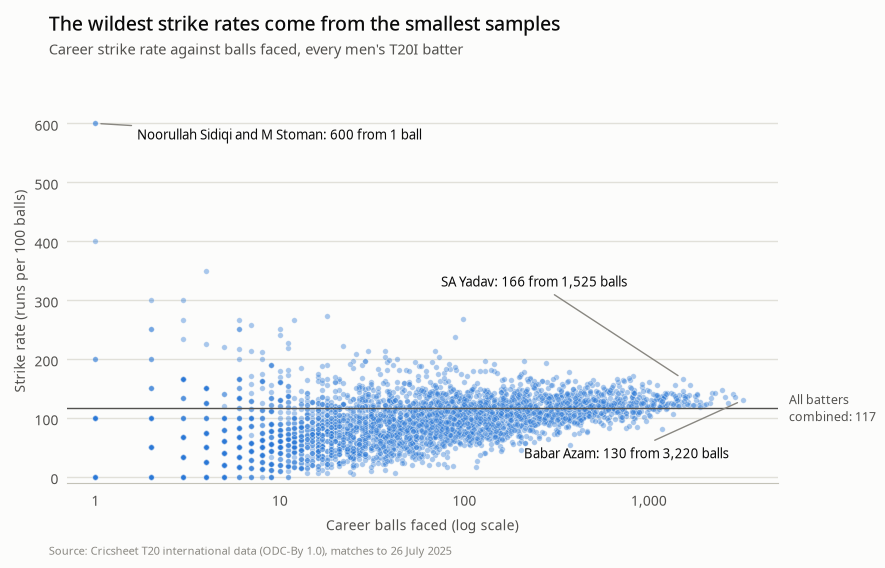

In [16]:
def plot_strike_rate_funnel(theme, bat, league_sr, source):
    fig, ax = new_figure(theme, figsize=(9, 5.8))
    fig.subplots_adjust(left=0.08, right=0.87, top=0.81, bottom=0.15)
    ax.set_xscale('log')
    ax.set_xlim(0.7, 5000)
    ax.set_ylim(-10, 640)
    ax.scatter(bat['balls'], bat['strike_rate'], s=16, color=theme['men'], alpha=0.4,
               edgecolor=theme['surface'], linewidth=0.5)
    ax.axhline(league_sr, color=theme['ink_2'], linewidth=1)
    ax.annotate(f'All batters\ncombined: {league_sr:.0f}', (1, league_sr), xycoords=('axes fraction', 'data'),
                xytext=(8, 0), textcoords='offset points', va='center', color=theme['ink_2'], fontsize=9)

    fastest = bat[bat['strike_rate'] == bat['strike_rate'].max()]
    best_regular = bat[bat['balls'] >= 1000].nlargest(1, 'strike_rate').iloc[0]
    most_balls = bat.nlargest(1, 'balls').iloc[0]
    callouts = [
        (fastest.iloc[0], f"{' and '.join(fastest['name'])}: {fastest['strike_rate'].iloc[0]:.0f} from 1 ball",
         (30, -8), 'left'),
        (best_regular, f"{best_regular['name']}: {best_regular['strike_rate']:.0f} from {best_regular['balls']:,} balls",
         (-40, 70), 'right'),
        (most_balls, f"{most_balls['name']}: {most_balls['strike_rate']:.0f} from {most_balls['balls']:,} balls",
         (-10, -38), 'right'),
    ]
    for player, text, offset, ha in callouts:
        ax.annotate(text, (player['balls'], player['strike_rate']), xytext=offset, textcoords='offset points',
                    ha=ha, va='center', color=theme['ink'], fontsize=9.5,
                    arrowprops=dict(arrowstyle='-', color=theme['muted'], linewidth=1, shrinkA=2, shrinkB=4))

    ax.set_xticks([1, 10, 100, 1000], ['1', '10', '100', '1,000'])
    ax.set_xlabel('Career balls faced (log scale)')
    ax.set_ylabel('Strike rate (runs per 100 balls)')
    titles(fig, theme, 'The wildest strike rates come from the smallest samples',
           "Career strike rate against balls faced, every men's T20I batter", source)
    return fig


save_both(plot_strike_rate_funnel, 'strike-rate-funnel', men_bat, league_sr, source)